# Berlin Housing Market 2020–2026
### Prices, rents and rental yields: a business analysis in Python

---

## 1. Introduction

**Context.** After the Covid-19 pandemic, the war in Ukraine, and the energy crisis, inflation in Europe rose sharply. To bring it down, the ECB raised interest rates from mid-2022, and mortgages became much more expensive. In this dataset, the average mortgage rate rises from 1.16% in December 2020 to 4.1% in mid-2023 and then eases to 3.8% in April 2026, while rents keep rising. [*Germany: Mortgage credit interest*](https://www.theglobaleconomy.com/Germany/mortgage_interest_rate/). Anyone deciding where to rent, buy or invest in Berlin needs to know what the data shows: how prices and rents moved, where, and what drives the differences.

**Goal.** Answer five business questions for people who rent, buy, or invest in Berlin, using real-looking listing data.

**Data.** [*Berlin Real Estate: Sales & Rentals 2020-2026*](https://www.kaggle.com/datasets/sergionefedov/berlin-real-estate-sales-and-rentals-2020-2026) on Kaggle (Sergio Nefedov). I use three of its files:

| File | What one row is | Used for |
|---|---|---|
| `kiez_prices_monthly.csv` | one district (Ortsteil) in one month | trends over time |
| `secondary_sales.csv` | one resale listing | resale prices |
| `rentals.csv` | one rental listing | rents |

**Tools.** Python, pandas, matplotlib.

**How to read this notebook.** Each question follows the same pattern: *Question → Chart or table → "Further analysis"*. Prices are **asking prices from listings** and medians are used throughout, because medians are not distorted by a few extreme listings.

### Project at a glance
The whole project on one page: where the data comes from, how it is prepared, the five questions answered, and what the reader gets at the end.

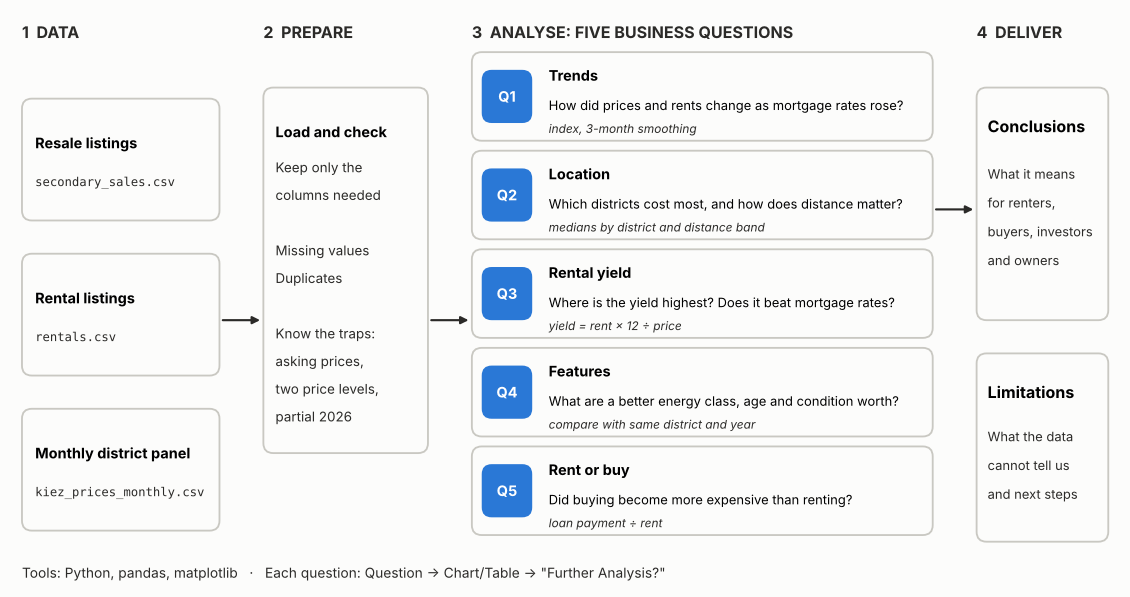

In [1]:
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

INK, MUTED, GRID, SURFACE, BLUE = "#000000", "#2b2a28", "#c9c8c2", "#fcfcfb", "#2a78d6"
FIG = "figures/"
os.makedirs(FIG, exist_ok=True)

fig, ax = plt.subplots(figsize=(13, 6.8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.set_xlim(0, 101); ax.set_ylim(0, 52); ax.axis("off")

def box(x, y, w, h, fill=SURFACE, edge=GRID, lw=1.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.9",
                                facecolor=fill, edgecolor=edge, linewidth=lw))

def arrow(x1, x2, y):
    ax.annotate("", xy=(x2, y), xytext=(x1, y),
                arrowprops={"arrowstyle": "-|>", "color": MUTED, "lw": 1.4, "shrinkA": 0, "shrinkB": 0})

# Column headers
for x, title in [(1, "1  DATA"), (23, "2  PREPARE"), (42, "3  ANALYSE: FIVE BUSINESS QUESTIONS"), (88, "4  DELIVER")]:
    ax.text(x, 50, title, fontsize=10.5, fontweight="bold", color=MUTED, va="center")

# 1 Data
for i, (name, sub) in enumerate([("Resale listings", "secondary_sales.csv"),
                                 ("Rental listings", "rentals.csv"),
                                 ("Monthly district panel", "kiez_prices_monthly.csv")]):
    y = 33 - i * 14
    box(1, y, 18, 11)
    ax.text(2.2, y + 7, name, fontsize=9.5, fontweight="bold", color=INK, va="center")
    ax.text(2.2, y + 3.4, sub, fontsize=8, color=MUTED, va="center", family="monospace")
arrow(19.3, 22.7, 24)

# 2 Prepare
box(23, 12, 15, 33)
ax.text(24.1, 41, "Load and check", fontsize=9.5, fontweight="bold", color=INK, va="center")
for j, line in enumerate(["Keep only the", "columns needed", "", "Missing values", "Duplicates", "", "Know the traps:", "asking prices,", "two price levels,", "partial 2026"]):
    ax.text(24.1, 37.8 - j * 2.5, line, fontsize=8.8, color=MUTED, va="center")
arrow(38.3, 41.7, 24)

# 3 Questions
qs = [("Q1", "Trends", "How did prices and rents change as mortgage rates rose?", "index, 3-month smoothing"),
      ("Q2", "Location", "Which districts cost most, and how does distance matter?", "medians by district and distance band"),
      ("Q3", "Rental yield", "Where is the yield highest? Does it beat mortgage rates?", "yield = rent × 12 ÷ price"),
      ("Q4", "Features", "What are a better energy class, age and condition worth?", "compare with same district and year"),
      ("Q5", "Rent or buy", "Did buying become more expensive than renting?", "loan payment ÷ rent")]
for i, (q, t, question, method) in enumerate(qs):
    y = 40.2 - i * 8.9
    box(42, y, 42, 8)
    ax.add_patch(FancyBboxPatch((42.9, y + 1.6), 4.6, 4.8, boxstyle="round,pad=0,rounding_size=0.9", facecolor=BLUE, edgecolor="none"))
    ax.text(45.2, y + 4, q, fontsize=9.5, fontweight="bold", color="white", ha="center", va="center")
    ax.text(49, y + 5.9, t, fontsize=9.5, fontweight="bold", color=INK, va="center")
    ax.text(49, y + 3.2, question, fontsize=8.5, color=INK, va="center")
    ax.text(49, y + 1.1, method, fontsize=7.8, color=MUTED, va="center", style="italic")
arrow(84.3, 87.7, 34)

# 4 Deliver
box(88, 24, 12, 21)
ax.text(89, 41.5, "Conclusions", fontsize=10.5, fontweight="bold", color=INK, va="center")
for j, line in enumerate(["What it means", "for renters,", "buyers, investors", "and owners"]):
    ax.text(89, 37.2 - j * 2.6, line, fontsize=8.5, color=MUTED, va="center")
box(88, 4, 12, 17)
ax.text(89, 17.5, "Limitations", fontsize=10.5, fontweight="bold", color=INK, va="center")
for j, line in enumerate(["What the data", "cannot tell us", "and next steps"]):
    ax.text(89, 13.5 - j * 2.6, line, fontsize=8.5, color=MUTED, va="center")

ax.text(1, 1.2, "Tools: Python, pandas, matplotlib   ·   Each question: Question → Chart/Table → \"Further Analysis?\"", fontsize=9, color=MUTED, va="center")
fig.savefig(FIG + "project_overview.png", dpi=300, bbox_inches="tight")
plt.show()

## Key findings


1. **Rents rose almost twice as fast as resale prices:** +43.5% vs. +23.0% between 2020 and 2025 (yearly averages).
2. **Prices barely reacted to the rate shock.** While the mortgage rate went from 1.1% to 4.1%, resale prices dipped only about 5% (index 125 → 119) and were back at 126 by April 2026.
3. **Location dominates.** The most expensive district costs 3.1× the cheapest per m² (Friedrichshain-Kreuzberg €6,155 vs. Marzahn-Hellersdorf €1,967). Price falls from €6,813 within 3 km of the centre to about €2,750 beyond 10 km, and then stops falling.
4. **Gross rental yields are thin:** 3.48% to 3.97% by district. All 12 districts beat today's 3.1% mortgage rate, but none beats the 4.1% rate of 2023. Cheaper outer districts yield the most.
5. **Features are priced in.** Compared with neighbours in the same district and year, flats in the worst energy class (H) sell for about 20% less and the best (A+) for about 50% more. Flats needing renovation sell for 22% less, fully refurbished ones for 14% more.
6. **Buying went from cheaper than renting to more expensive.** In 2020–21 the monthly loan payment for a flat was about 19% below the rent. Since January 2022 it has been higher, peaking at 1.42× the rent in September 2023 and standing at 1.13× in April 2026. In 2025 buying and renting cost about the same in most districts (0.95× to 1.12×).

## 2. Business questions

| # | Business question | Who cares | Decision it supports |
|---|---|---|---|
| **Q1** | How did prices and rents change from 2020 to 2026, and what happened when mortgage rates rose? | Everyone | Timing; rent or buy |
| **Q2** | Which districts are the most and least expensive, and how does price change with distance from the centre? | Buyers, renters | Where to look |
| **Q3** | Where is the gross rental yield highest, and does it cover the mortgage rate? | Investors | Where to buy to let |
| **Q4** | How much more are flats with a better energy class, a newer building or a better condition worth? | Owners, investors, buyers | Which features justify a higher price |
| **Q5** | Is it cheaper to rent or to buy, and did that change when mortgage rates rose? | Renters, buyers | Rent or buy |

## 3. Data preparation
### 3.1 Load only what is needed
The files have many columns. For these five questions I keep a small set of them. *To run this notebook, put the three CSV files in a folder called `data/` next to it.*

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates

DATA, FIG = "data/", "figures/"
os.makedirs(FIG, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# ---- Chart style: one colour per thing (blue = resale, green = rent), calm grid ----------------------------
BLUE, AQUA, ORANGE = "#2a78d6", "#1baf7a", "#eb6834"
INK, MUTED, GRID, SURFACE = "#1a1a19", "#52514e", "#e4e3de", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})

def tidy(ax, grid="y"):
    """Keep only light gridlines in one direction."""
    ax.grid(False)
    ax.grid(True, axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def save(fig, name):
    """Save a copy in figures/ (for the README) and show the chart."""
    fig.savefig(f"{FIG}{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# ---- Columns kept from each file ---------------------------------------------------------------------------
sales = pd.read_csv(DATA + "secondary_sales.csv", parse_dates=["date_listed"],
                    usecols=["id", "date_listed", "bezirk", "ortsteil", "kiez_premium", "to_brandenburg_gate_km",
                             "price_per_m2_eur", "building_era", "energy_class", "condition"])
rent = pd.read_csv(DATA + "rentals.csv", parse_dates=["date_listed"],
                   usecols=["id", "date_listed", "bezirk", "ortsteil", "kiez_premium", "to_brandenburg_gate_km",
                            "rent_per_m2_kalt_eur", "energy_class"])
panel = pd.read_csv(DATA + "kiez_prices_monthly.csv",
                    usecols=["year_month", "ortsteil", "secondary_price_per_m2_eur",
                             "kaltmiete_per_m2_monthly_eur", "avg_mortgage_rate_pct"])

sales["year"] = sales.date_listed.dt.year
rent["year"] = rent.date_listed.dt.year

pd.DataFrame({
    "table": ["secondary_sales", "rentals", "kiez_prices_monthly"],
    "rows": [len(sales), len(rent), len(panel)],
    "columns kept": [sales.shape[1], rent.shape[1], panel.shape[1]],
    "period": [f"{sales.date_listed.min():%Y-%m} to {sales.date_listed.max():%Y-%m}",
               f"{rent.date_listed.min():%Y-%m} to {rent.date_listed.max():%Y-%m}",
               f"{panel.year_month.min()} to {panel.year_month.max()}"],
})

,table,rows,columns kept,period
0,secondary_sales,50000,11,2020-01 to 2026-04
1,rentals,30000,9,2020-01 to 2026-04
2,kiez_prices_monthly,6232,5,2020-01 to 2026-04


### 3.2 Quality checks
Before analysing, I check whether the data is complete and unique.

In [3]:
pd.DataFrame({
    "table": ["secondary_sales", "rentals", "kiez_prices_monthly"],
    "missing values": [int(sales.isna().sum().sum()), int(rent.isna().sum().sum()), int(panel.isna().sum().sum())],
    "duplicate ids / rows": [int(sales.id.duplicated().sum()), int(rent.id.duplicated().sum()),
                             int(panel.duplicated(["ortsteil", "year_month"]).sum())],
    "districts (Ortsteile)": [sales.ortsteil.nunique(), rent.ortsteil.nunique(), panel.ortsteil.nunique()],
})

,table,missing values,duplicate ids / rows,districts (Ortsteile)
0,secondary_sales,0,0,82
1,rentals,0,0,82
2,kiez_prices_monthly,0,0,82


The data is complete and unique. Three things to keep in mind while reading the results:

1. **These are listing (asking) prices**, not the prices at which flats were sold.
2. **The monthly panel and the listing files are on different price levels** (the panel is higher). So I use the panel only for *trends over time* (Q1 and the first half of Q5) and the listing files for *comparisons* (Q2–Q4 and the second half of Q5), and never mix the two in one calculation.
3. **The last period is incomplete.** Data ends in April 2026, so 2026 is only a partial year and I do not compare it with full years.

---
## 4. Analysis

### Q1 · How did prices and rents change from 2020 to 2026, and what happened when mortgage rates rose?

**Approach.** For each month I take the average across all 82 districts from the monthly panel. I then express price and rent as an **index** (average of Jan–Mar 2020 = 100) so that both can be shown on the same scale, and I smooth with a 3-month average to reduce month-to-month noise.

In [4]:
# One row per month: average across all districts
monthly = panel.groupby("year_month").agg(price=("secondary_price_per_m2_eur", "mean"),
                                          rent=("kaltmiete_per_m2_monthly_eur", "mean"),
                                          mortgage_rate=("avg_mortgage_rate_pct", "first"))
monthly.index = pd.to_datetime(monthly.index)

# Index: average of Jan–Mar 2020 = 100, then 3-month smoothing
base = monthly.loc["2020-01":"2020-03", ["price", "rent"]].mean()
index = (monthly[["price", "rent"]] / base * 100).rolling(3, center=True, min_periods=2).mean()

# Yearly averages (2026 is only Jan–Apr, so it is left out of the comparison)
yearly = monthly.groupby(monthly.index.year).mean()
yearly.index.name = "year"
display(yearly.rename(columns={"price": "resale price €/m²", "rent": "cold rent €/m²", "mortgage_rate": "mortgage rate %"}))
chg = (yearly.loc[2025, ["price", "rent"]] / yearly.loc[2020, ["price", "rent"]] - 1) * 100
print(f"Change 2020 → 2025 (full-year averages):  resale price {chg.price:+.1f}%   cold rent {chg.rent:+.1f}%")

# The dip: highest point in 2021–22, lowest point afterwards
peak = index.price["2021-06":"2022-12"].idxmax()
trough = index.price[peak:"2024-12"].idxmin()
print(f"Resale price index peaked in {peak:%Y-%m} at {index.price[peak]:.0f}, fell to {index.price[trough]:.0f} in {trough:%Y-%m} "
      f"({index.price[trough] / index.price[peak] - 1:+.1%}), and by {index.price.index[-1]:%Y-%m} was back at {index.price.iloc[-1]:.0f}.")
print(f"Mortgage rate: {monthly.mortgage_rate.iloc[0]:.1f}% in {monthly.index[0]:%Y-%m} → highest {monthly.mortgage_rate.max():.1f}% "
      f"in {monthly.mortgage_rate.idxmax():%Y-%m} → {monthly.mortgage_rate.iloc[-1]:.1f}% in {monthly.index[-1]:%Y-%m}")

,resale price €/m²,cold rent €/m²,mortgage rate %
year,,,
2020,"4,599.49",11.77,1.10
2021,"4,949.16",12.55,1.10
2022,"5,625.86",14.18,2.60
2023,"5,430.27",15.21,3.97
2024,"5,429.97",15.92,3.68
2025,"5,656.73",16.89,3.20
2026,"5,709.15",17.12,3.10


Change 2020 → 2025 (full-year averages):  resale price +23.0%   cold rent +43.5%
Resale price index peaked in 2022-02 at 125, fell to 119 in 2024-01 (-5.1%), and by 2026-04 was back at 126.
Mortgage rate: 1.1% in 2020-01 → highest 4.1% in 2023-07 → 3.1% in 2026-04


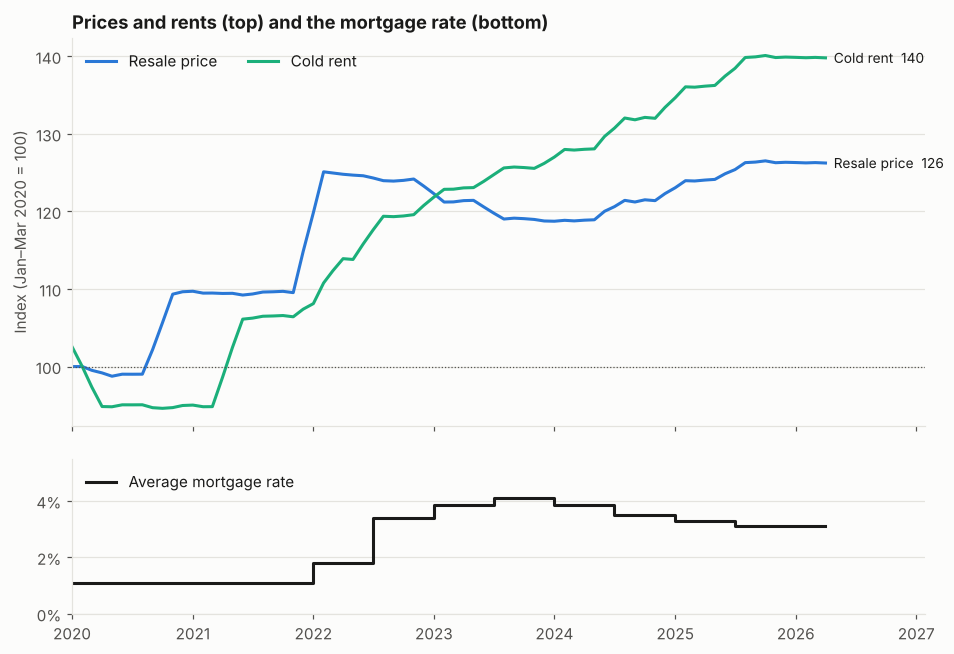

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.8), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.12})

# Top: price and rent index
for col, colour, label in [("price", BLUE, "Resale price"), ("rent", AQUA, "Cold rent")]:
    ax1.plot(index.index, index[col], color=colour, label=label)
    ax1.text(index.index[-1] + pd.Timedelta(days=25), index[col].iloc[-1], f"{label}  {index[col].iloc[-1]:.0f}",
             va="center", fontsize=9)
ax1.axhline(100, color=MUTED, lw=0.8, ls=":")
ax1.set_ylabel("Index (Jan–Mar 2020 = 100)")
ax1.set_title("Prices and rents (top) and the mortgage rate (bottom)")
ax1.legend(loc="upper left", ncol=2)
tidy(ax1)

# Bottom: mortgage rate
ax2.step(monthly.index, monthly.mortgage_rate, where="post", color=INK, label="Average mortgage rate")
ax2.set_ylim(0, 5.5); ax2.set_yticks([0, 2, 4])
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
ax2.legend(loc="upper left")
ax2.set_xlim(index.index[0], index.index[-1] + pd.Timedelta(days=300))
ax2.xaxis.set_major_locator(mdates.YearLocator()); ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
tidy(ax2)
save(fig, "q1_trends")

**Further Analysis?**

- **Rent pressure is the bigger story than prices.** Between 2020 and 2025 the average cold rent rose 43.5% (from €11.77 to €16.89 per m²), almost twice the 23.0% rise in resale prices (from €4,599 to €5,657 per m²).
- **The rate shock caused only a small, temporary dip in prices.** Resale prices peaked in early 2022 (index 125), fell about 5% to 119 by January 2024 while the mortgage rate climbed from 1.1% to 4.1%, and were back at 126 by April 2026, even though the rate is still almost three times its 2020 level (3.1%). This shows that the two moved together for a while, but it does not prove that rates caused the dip.
- **For a buyer,** waiting for a price crash would not have paid off in this data. What changed for buyers was the cost of the loan, not the price of the flat.

---
### Q2 · Which districts are most and least expensive, and how does price change with distance from the centre?

**Approach.** Median price and rent per m² for each of Berlin's 12 districts (Bezirke), then median price by distance band from the Brandenburg Gate. Each listing also carries a "kiez tier" (low / medium / high), a simple label for how sought-after the neighbourhood is.

,resale €/m²,rent €/m²
bezirk,,
Friedrichshain-Kreuzberg,"6,155.00",18.08
Mitte,"6,000.00",17.40
Charlottenburg-Wilmersdorf,"5,861.00",17.03
Steglitz-Zehlendorf,"5,058.00",16.00
Tempelhof-Schöneberg,"3,800.00",11.45
Pankow,"3,523.00",11.26
Treptow-Köpenick,"3,294.00",10.62
Neukölln,"3,076.00",9.48
Reinickendorf,"2,981.00",9.41


Most expensive district (Friedrichshain-Kreuzberg) vs. cheapest (Marzahn-Hellersdorf): 3.1× the price per m²


,resale €/m²,rent €/m²
kiez_premium,,
high,"6,079.50",18.25
medium,"3,534.00",11.05
low,"2,527.00",8.19


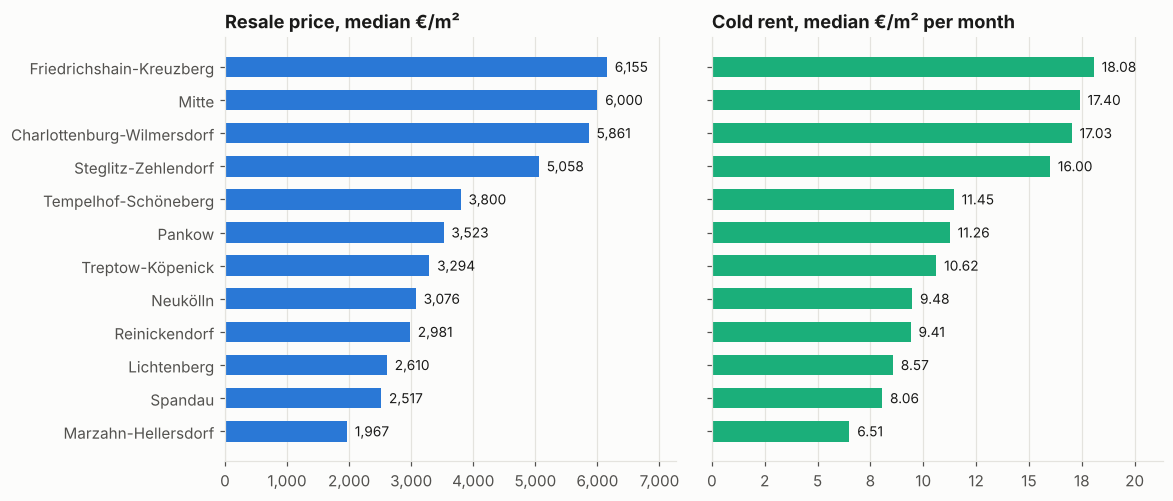

In [6]:
bezirk = pd.DataFrame({
    "resale €/m²": sales.groupby("bezirk").price_per_m2_eur.median(),
    "rent €/m²": rent.groupby("bezirk").rent_per_m2_kalt_eur.median(),
}).sort_values("resale €/m²", ascending=False)
display(bezirk.round({"resale €/m²": 0, "rent €/m²": 2}))

ratio = bezirk["resale €/m²"].iloc[0] / bezirk["resale €/m²"].iloc[-1]
print(f"Most expensive district ({bezirk.index[0]}) vs. cheapest ({bezirk.index[-1]}): {ratio:.1f}× the price per m²")

tiers = pd.DataFrame({"resale €/m²": sales.groupby("kiez_premium").price_per_m2_eur.median(),
                      "rent €/m²": rent.groupby("kiez_premium").rent_per_m2_kalt_eur.median()}).loc[["high", "medium", "low"]]
display(tiers)

order = bezirk.index[::-1]                      # so the most expensive district is at the top
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, col, colour, fmt, title in [(axes[0], "resale €/m²", BLUE, "{:,.0f}", "Resale price, median €/m²"),
                                    (axes[1], "rent €/m²", AQUA, "{:.2f}", "Cold rent, median €/m² per month")]:
    values = bezirk.loc[order, col]
    ax.barh(values.index, values.values, color=colour, height=0.62)
    for i, v in enumerate(values.values):
        ax.text(v, i, "  " + fmt.format(np.round(v, 2)), va="center", fontsize=9)
    ax.set_title(title); ax.set_xlim(0, values.max() * 1.18)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    tidy(ax, "x")
save(fig, "q2_districts")

,median,listings
to_brandenburg_gate_km,,
0–3 km,"6,813.00",2561
3–6 km,"5,169.00",7183
6–10 km,"3,641.00",16775
10–15 km,"2,752.00",16051
15+ km,"2,774.00",7430


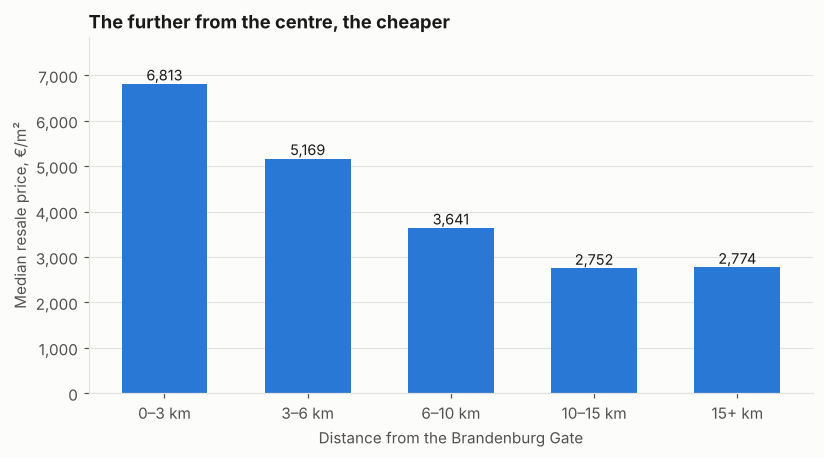

In [7]:
# Price by distance from the centre
bands = pd.cut(sales.to_brandenburg_gate_km, [0, 3, 6, 10, 15, 40], labels=["0–3 km", "3–6 km", "6–10 km", "10–15 km", "15+ km"])
dist = sales.groupby(bands, observed=True).price_per_m2_eur.agg(median="median", listings="count")
display(dist.round({"median": 0}))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(dist.index.astype(str), dist["median"], color=BLUE, width=0.6)
for i, v in enumerate(dist["median"]):
    ax.text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9.5)
ax.set_ylim(0, dist["median"].max() * 1.15)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Distance from the Brandenburg Gate"); ax.set_ylabel("Median resale price, €/m²")
ax.set_title("The further from the centre, the cheaper")
tidy(ax)
save(fig, "q2_distance")

**Further Analysis?**

- **Berlin is a two-tier market.** Four districts (Friedrichshain-Kreuzberg, Mitte, Charlottenburg-Wilmersdorf, Steglitz-Zehlendorf) cost more than €5,000 per m². The other eight cost €3,800 or less. The most expensive district is 3.1× the cheapest.
- **Rents follow prices.** The ranking of districts is identical for rents and for resale prices (from €18.08 per m² in Friedrichshain-Kreuzberg to €6.51 in Marzahn-Hellersdorf).
- **The "kiez tier" label captures a lot.** High-tier neighbourhoods cost 2.4× low-tier ones for resale (€6,080 vs. €2,527 per m²) and 2.2× for rent (€18.25 vs. €8.19).
- **Distance matters a lot, up to a point.** Median price falls from €6,813 within 3 km of the centre to €2,752 at 10–15 km (about 60% lower), and then stays flat (€2,774 beyond 15 km). For buyers on a budget, going beyond 10 km does not make a flat cheaper, so other factors (transport, size, condition) should decide.

---
### Q3 · Where is the gross rental yield highest, and does it cover the mortgage rate?

**Approach.** The **gross rental yield** is the annual rent as a share of the purchase price:

> yield = (monthly rent per m² × 12) ÷ price per m²

I compute it for each district from the median rent and median resale price. I compare it with the mortgage rate: if the yield is *below* the mortgage rate, the flat's rent does not even cover the interest on a loan (before any costs).

,price €/m²,rent €/m²,yield %
bezirk,,,
Marzahn-Hellersdorf,"1,967.00",6.51,3.97
Lichtenberg,"2,610.00",8.57,3.94
Treptow-Köpenick,"3,294.00",10.62,3.87
Spandau,"2,517.00",8.06,3.84
Pankow,"3,523.00",11.26,3.84
Steglitz-Zehlendorf,"5,058.00",16.00,3.80
Reinickendorf,"2,981.00",9.41,3.79
Neukölln,"3,076.00",9.48,3.70
Tempelhof-Schöneberg,"3,800.00",11.45,3.62


Yield range: 3.48% to 3.97%
Districts with a yield above today's mortgage rate (3.1%): 12 of 12
Districts with a yield above the 4.1% peak mortgage rate: 0 of 12


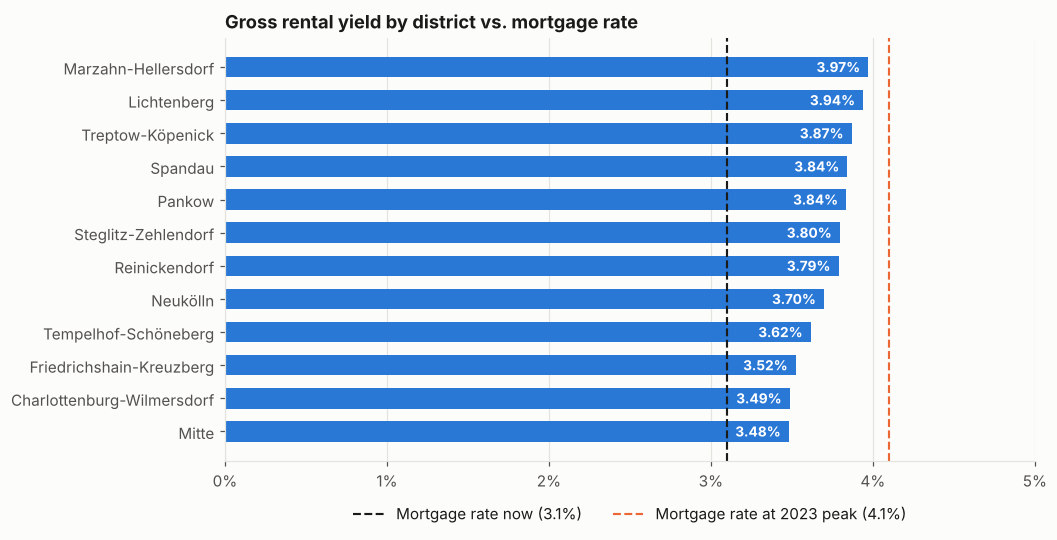

In [8]:
yields = pd.DataFrame({"price €/m²": sales.groupby("bezirk").price_per_m2_eur.median(),
                       "rent €/m²": rent.groupby("bezirk").rent_per_m2_kalt_eur.median()})
yields["yield %"] = yields["rent €/m²"] * 12 / yields["price €/m²"] * 100
yields = yields.sort_values("yield %", ascending=False)

mortgage_now = monthly.mortgage_rate.iloc[-1]           # latest value in the data
mortgage_peak = monthly.mortgage_rate.max()             # highest value (2023)
display(yields.round({"price €/m²": 0, "rent €/m²": 2, "yield %": 2}))
print(f"Yield range: {yields['yield %'].min():.2f}% to {yields['yield %'].max():.2f}%")
print(f"Districts with a yield above today's mortgage rate ({mortgage_now:.1f}%): {(yields['yield %'] > mortgage_now).sum()} of {len(yields)}")
print(f"Districts with a yield above the {mortgage_peak:.1f}% peak mortgage rate: {(yields['yield %'] > mortgage_peak).sum()} of {len(yields)}")

fig, ax = plt.subplots(figsize=(9.5, 5))
values = yields["yield %"][::-1]
ax.barh(values.index, values.values, color=BLUE, height=0.62)
for i, v in enumerate(values.values):
    ax.text(v - 0.05, i, f"{v:.2f}%", va="center", ha="right", fontsize=9, color="white", fontweight="bold")
ax.axvline(mortgage_now, color=INK, lw=1.4, ls="--", label=f"Mortgage rate now ({mortgage_now:.1f}%)")
ax.axvline(mortgage_peak, color=ORANGE, lw=1.4, ls="--", label=f"Mortgage rate at 2023 peak ({mortgage_peak:.1f}%)")
ax.set_xlim(0, 5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2)
ax.set_title("Gross rental yield by district vs. mortgage rate")
tidy(ax, "x")
save(fig, "q3_yield")

**Further analysis?**

- **Cheaper districts yield more.** The highest yield is in Marzahn-Hellersdorf (3.97%) and Lichtenberg (3.94%), the lowest in Mitte (3.48%), Charlottenburg-Wilmersdorf (3.49%) and Friedrichshain-Kreuzberg (3.52%). In expensive areas the price rises faster than the rent.
- **The margin over borrowing costs is thin.** All 12 districts are above today's mortgage rate of 3.1% (by 0.4 to 0.9 percentage points) but none is above the 4.1% of mid-2023. And this is the *gross* yield, before maintenance, vacancies, taxes and purchase costs.
- **The mortgage rate matters more than the district.** The gap between the best and the worst district is 0.5 percentage points, while the mortgage rate moved by 3 percentage points over the period. A mortgage rate that is 1 point lower improves the margin between yield and interest by 1 point, twice the 0.5-point gap between the best and worst district.
- **Caveat:** these yields use medians and do not account for flat size or age. In a more detailed version of this analysis I adjusted for those and found the same pattern (lowest in the centre, highest at the edge).

---
### Q4 · How much more are flats with a better energy class, a newer building or a better condition worth?

**The problem with simple averages.** Good energy classes and new buildings are more common in expensive areas, so a plain average mixes "better flat" with "better location".

**A simple fix.** Compare every flat with its **neighbours**: its price per m² divided by the median price per m² of all flats listed in the *same district and year*. A value of +20% then means "20% more expensive than similar-location flats in the same year". Averaging this by energy class, building age and condition shows the effect of each feature with location and timing largely removed.

In [9]:
# Price relative to the median of the same district (Ortsteil) and year
sales["vs_local_%"] = (sales.price_per_m2_eur / sales.groupby(["ortsteil", "year"]).price_per_m2_eur.transform("median") - 1) * 100
rent["vs_local_%"] = (rent.rent_per_m2_kalt_eur / rent.groupby(["ortsteil", "year"]).rent_per_m2_kalt_eur.transform("median") - 1) * 100

energy_order = ["A_plus", "A", "B", "C", "D", "E", "F", "G", "H"]
energy = pd.DataFrame({"resale": sales.groupby("energy_class")["vs_local_%"].median(),
                       "rent": rent.groupby("energy_class")["vs_local_%"].median()}).reindex(energy_order)
energy.index = ["A+", "A", "B", "C", "D", "E", "F", "G", "H"]

era_order = ["post_war_1949_1990", "modern_1990_2010", "altbau_pre_1949", "new_post_2010"]
era = sales.groupby("building_era")["vs_local_%"].median().reindex(era_order)
era.index = ["1949–1990", "1990–2010", "Altbau (<1949)", "New (2010+)"]

cond_order = ["renovierungsbedürftig", "renoviert", "modernisiert", "saniert", "kernsaniert"]
cond = sales.groupby("condition")["vs_local_%"].median().reindex(cond_order)
cond.index = ["Needs renovation", "Renoviert", "Modernisiert", "Saniert", "Kernsaniert"]

display(energy.rename(columns={"resale": "resale vs. local median, %", "rent": "rent vs. local median, %"}).style.format("{:.1f}"))
display(era.to_frame("resale vs. local median, %").style.format("{:.1f}"))
display(cond.to_frame("resale vs. local median, %").style.format("{:.1f}"))

,"resale vs. local median, %","rent vs. local median, %"
A+,50.0,45.4
A,38.9,35.0
B,25.0,21.3
C,11.7,10.2
D,2.4,1.9
E,-2.1,-1.2
F,-7.5,-5.5
G,-14.4,-12.6
H,-20.2,-18.9


,"resale vs. local median, %"
1949–1990,-11.1
1990–2010,17.1
Altbau (<1949),-2.2
New (2010+),42.7


,"resale vs. local median, %"
Needs renovation,-22.4
Renoviert,-5.3
Modernisiert,0.7
Saniert,6.2
Kernsaniert,13.5


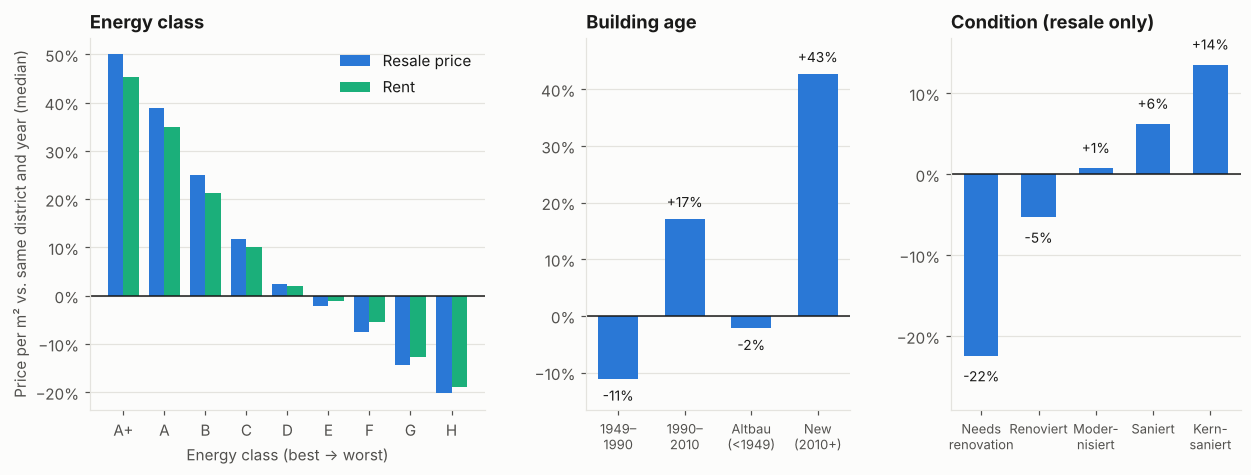

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1.5, 1, 1.1], "wspace": 0.32})

# Line breaks are used only for the chart labels, so the tables above stay clean
era_labels = ["1949–\n1990", "1990–\n2010", "Altbau\n(<1949)", "New\n(2010+)"]
cond_labels = ["Needs\nrenovation", "Renoviert", "Moder-\nnisiert", "Saniert", "Kern-\nsaniert"]

# Energy class: resale and rent
ax = axes[0]
x = np.arange(len(energy)); w = 0.38
ax.bar(x - w / 2, energy.resale, width=w, color=BLUE, label="Resale price")
ax.bar(x + w / 2, energy.rent, width=w, color=AQUA, label="Rent")
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(x); ax.set_xticklabels(energy.index); ax.set_xlabel("Energy class (best → worst)")
ax.set_title("Energy class"); ax.legend(loc="upper right")

# Building age
ax = axes[1]
ax.bar(range(len(era)), era.values, color=BLUE, width=0.6)
ax.axhline(0, color=INK, lw=1)
for i, v in enumerate(era.values):
    ax.text(i, v + (1.5 if v >= 0 else -1.5), f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.set_xticks(range(len(era))); ax.set_xticklabels(era_labels, fontsize=8.5); ax.set_title("Building age")
ax.set_ylim(era.min() * 1.5, era.max() * 1.15)

# Condition
ax = axes[2]
ax.bar(range(len(cond)), cond.values, color=BLUE, width=0.6)
ax.axhline(0, color=INK, lw=1)
for i, v in enumerate(cond.values):
    ax.text(i, v + (1.5 if v >= 0 else -1.5), f"{v:+.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.set_xticks(range(len(cond))); ax.set_xticklabels(cond_labels, fontsize=8.5); ax.set_title("Condition (resale only)")
ax.set_ylim(cond.min() * 1.3, cond.max() * 1.25)

for ax in axes:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=0)); tidy(ax)
axes[0].set_ylabel("Price per m² vs. same district and year (median)")
save(fig, "q4_features")

**Further Analysis?**

- **Energy class is clearly priced in, for resale and for rent.** Compared with similar-location flats in the same year, class A+ flats are about 50% more expensive and class H about 20% cheaper. Rents follow almost exactly the same pattern (+45% for A+, −19% for H), so landlords as well as sellers are paid for efficiency.
- **Newer buildings are worth much more,** and the weakest segment is the post-war housing of 1949–1990 (−11%), not the pre-1949 Altbau (−2%).
- **Condition matters for the sale price.** Flats needing renovation sell for 22% less than their neighbours and fully refurbished ones (kernsaniert) for 14% more, a gap of about 36 percentage points.
- **Important caution: these effects overlap.** New buildings tend to have a good energy class *and* good condition, so the bars cannot be added together, and they show what flats *with* a feature cost, not what *adding* the feature would be worth. When I held all other features constant in the longer version of this analysis, the energy-class effect was smaller (about +20% for A+ and −21% for H compared with class E).
- **For an owner,** a flat in a poor energy class or in poor condition sells at a clear discount, so a renovation might pay off, but the data contains no renovation costs, so no profit can be claimed.

---
### Q5 · Is it cheaper to rent or to buy, and did that change when mortgage rates rose?

**Approach.** For a flat bought with a loan, the monthly cost is the loan payment. I compare it with the cold rent for the same m². The assumptions are deliberately simple and written at the top of the code so anyone can change them:

- 20% of the price is paid in cash, 80% is a loan,
- the loan costs the average mortgage rate of that month **plus 2% repayment per year** (a typical German annuity loan),
- monthly payment per m² = price per m² × 80% × (mortgage rate + 2%) ÷ 12.

I then divide this payment by the rent. A value **below 1** means the loan payment is lower than the rent, **above 1** means it is higher. I first look at the trend over time (monthly panel), then at the districts for the latest full year (listings).

In [11]:
# ---- Assumptions (change them and re-run) -----------------------------------------------------------------
DOWN = 0.20     # share of the price paid in cash; the rest is a loan
REPAY = 2.0     # initial repayment in % of the loan per year

def monthly_payment(price_m2, rate_pct):
    """Monthly loan payment per m²: loan × (interest rate + repayment) ÷ 12."""
    return price_m2 * (1 - DOWN) * (rate_pct + REPAY) / 100 / 12

# ---- Trend over time (monthly panel, average of all districts) ---------------------------------------------
bvr = monthly[["price", "rent", "mortgage_rate"]].copy()
bvr["payment"] = monthly_payment(bvr.price, bvr.mortgage_rate)
bvr["ratio"] = bvr.payment / bvr.rent

by_year = bvr.groupby(bvr.index.year).mean()
by_year.index.name = "year"
by_year["payment ÷ rent"] = by_year.payment / by_year.rent
by_year["years of rent = price"] = by_year.price / (by_year.rent * 12)
display(by_year.rename(columns={"payment": "loan payment €/m²", "rent": "cold rent €/m²", "mortgage_rate": "mortgage rate %"})
        [["mortgage rate %", "loan payment €/m²", "cold rent €/m²", "payment ÷ rent", "years of rent = price"]])

first_above = bvr.index[bvr.ratio > 1][0]
print(f"Payment ÷ rent: {bvr.ratio.iloc[0]:.2f} in {bvr.index[0]:%Y-%m} (loan payment below rent)")
print(f"First month with the loan payment above the rent: {first_above:%Y-%m}")
print(f"Highest: {bvr.ratio.max():.2f} in {bvr.ratio.idxmax():%Y-%m}  →  latest: {bvr.ratio.iloc[-1]:.2f} in {bvr.index[-1]:%Y-%m}")
print(f"Change 2020 → 2025 (yearly averages): loan payment {by_year.loc[2025, 'payment'] / by_year.loc[2020, 'payment'] - 1:+.0%}, "
      f"cold rent {by_year.loc[2025, 'rent'] / by_year.loc[2020, 'rent'] - 1:+.0%}")

# Only part of the payment is a real cost: the repayment part builds up the owner's equity
interest = bvr.price * (1 - DOWN) * bvr.mortgage_rate / 100 / 12
print(f"2025: interest part of the payment €{interest['2025'].mean():.2f} per m² (the rest is repayment) vs. rent €{by_year.loc[2025, 'rent']:.2f} per m²")

,mortgage rate %,loan payment €/m²,cold rent €/m²,payment ÷ rent,years of rent = price
year,,,,,
2020,1.10,9.51,11.77,0.81,32.57
2021,1.10,10.23,12.55,0.81,32.86
2022,2.60,17.24,14.18,1.22,33.05
2023,3.97,21.63,15.21,1.42,29.75
2024,3.68,20.54,15.92,1.29,28.43
2025,3.20,19.61,16.89,1.16,27.91
2026,3.10,19.41,17.12,1.13,27.78


Payment ÷ rent: 0.74 in 2020-01 (loan payment below rent)
First month with the loan payment above the rent: 2022-01
Highest: 1.42 in 2023-09  →  latest: 1.13 in 2026-04
Change 2020 → 2025 (yearly averages): loan payment +106%, cold rent +44%
2025: interest part of the payment €12.06 per m² (the rest is repayment) vs. rent €16.89 per m²


In [12]:
# ---- Districts, latest full year (listing files, medians) --------------------------------------------------
rate_2025 = monthly.loc["2025", "mortgage_rate"].mean()
by_district = pd.DataFrame({"price €/m²": sales[sales.year == 2025].groupby("bezirk").price_per_m2_eur.median(),
                            "rent €/m²": rent[rent.year == 2025].groupby("bezirk").rent_per_m2_kalt_eur.median()})
by_district["loan payment €/m²"] = monthly_payment(by_district["price €/m²"], rate_2025)
by_district["payment ÷ rent"] = by_district["loan payment €/m²"] / by_district["rent €/m²"]
by_district = by_district.sort_values("payment ÷ rent")
display(by_district.round({"price €/m²": 0, "rent €/m²": 2, "loan payment €/m²": 2, "payment ÷ rent": 2}))

berlin = monthly_payment(sales[sales.year == 2025].price_per_m2_eur.median(), rate_2025) / rent[rent.year == 2025].rent_per_m2_kalt_eur.median()
print(f"2025 mortgage rate used: {rate_2025:.1f}%")
print(f"Districts where the payment is below the rent: {(by_district['payment ÷ rent'] < 1).sum()} of {len(by_district)}; "
      f"range {by_district['payment ÷ rent'].min():.2f} to {by_district['payment ÷ rent'].max():.2f}")
print(f"Berlin overall, listing files, 2025: {berlin:.2f}   vs.  monthly panel, 2025: {by_year.loc[2025, 'payment ÷ rent']:.2f}")

,price €/m²,rent €/m²,loan payment €/m²,payment ÷ rent
bezirk,,,,
Lichtenberg,"2,814.00",10.28,9.76,0.95
Treptow-Köpenick,"3,492.00",12.42,12.10,0.97
Steglitz-Zehlendorf,"5,285.00",18.52,18.32,0.99
Reinickendorf,"3,136.00",10.89,10.87,1.00
Marzahn-Hellersdorf,"2,071.00",7.17,7.18,1.00
Spandau,"2,705.00",9.31,9.38,1.01
Pankow,"3,835.00",12.88,13.29,1.03
Neukölln,"3,274.00",10.85,11.35,1.05
Friedrichshain-Kreuzberg,"6,499.00",21.39,22.53,1.05


2025 mortgage rate used: 3.2%
Districts where the payment is below the rent: 4 of 12; range 0.95 to 1.12
Berlin overall, listing files, 2025: 1.01   vs.  monthly panel, 2025: 1.16


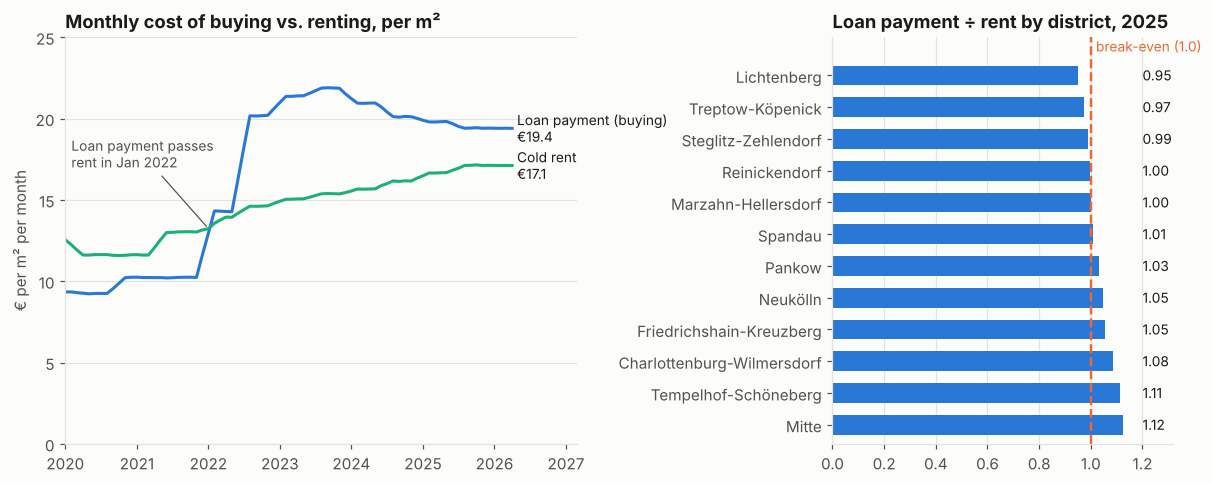

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.6})

# Left: monthly loan payment vs. rent (3-month smoothing, as in Q1)
sm = bvr[["payment", "rent"]].rolling(3, center=True, min_periods=2).mean()
for col, colour, label in [("payment", BLUE, "Loan payment (buying)"), ("rent", AQUA, "Cold rent")]:
    ax1.plot(sm.index, sm[col], color=colour)
    ax1.text(sm.index[-1] + pd.Timedelta(days=25), sm[col].iloc[-1], f"{label}\n€{sm[col].iloc[-1]:.1f}", va="center", fontsize=9)
cross = first_above                              # first month with payment > rent (from the cell above)
ax1.annotate(f"Loan payment passes\nrent in {cross:%b %Y}", xy=(cross, sm.rent[cross]), xytext=(pd.Timestamp("2020-02-01"), 17),
             fontsize=9, color=MUTED, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax1.set_ylim(0, 25); ax1.set_xlim(sm.index[0], sm.index[-1] + pd.Timedelta(days=330))
ax1.set_ylabel("€ per m² per month")
ax1.set_title("Monthly cost of buying vs. renting, per m²")
ax1.xaxis.set_major_locator(mdates.YearLocator()); ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
tidy(ax1)

# Right: payment ÷ rent by district, 2025
v = by_district["payment ÷ rent"][::-1]
ax2.barh(v.index, v.values, color=BLUE, height=0.62)
for i, x in enumerate(v.values):
    ax2.text(1.2, i, f"{x:.2f}", va="center", ha="left", fontsize=9)
ax2.axvline(1, color=ORANGE, lw=1.6, ls="--")
ax2.text(1.02, len(v) - 0.35, "break-even (1.0)", color=ORANGE, fontsize=9, ha="left", va="bottom")
ax2.set_xlim(0, 1.32); ax2.set_ylim(-0.6, len(v) + 0.2)
ax2.set_title("Loan payment ÷ rent by district, 2025")
tidy(ax2, "x")
save(fig, "q5_buy_vs_rent")

**Further Analysis?**

- **The rate shock flipped the monthly maths.** In 2020 and 2021 (mortgage rate 1.1%) the loan payment was about 19% below the rent (€9.51 vs. €11.77 per m² in 2020). It passed the rent in January 2022, peaked at 1.42× the rent in September 2023 and was at 1.13× in April 2026.
- **It was the interest rate, not the price.** From 2020 to 2025 the loan payment per m² rose 106%, while the resale price rose 23% and the rent 44%. The rest comes from the loan itself: interest plus repayment was 68% higher (5.2% vs. 3.1% of the loan per year).
- **Rents catching up closed part of the gap.** The ratio fell from 1.42 in 2023 to 1.16 in 2025 (yearly averages), and a flat now equals about 28 years of rent, down from about 33 in 2020.
- **By district in 2025 it is close to break-even.** The ratio ranges from 0.95 (Lichtenberg) to 1.12 (Mitte). Four districts are at or just below 1.0 (Lichtenberg, Treptow-Köpenick, Steglitz-Zehlendorf, Reinickendorf), and the centre is the least favourable for buyers (Mitte 1.12, Tempelhof-Schöneberg 1.11). This is the yield idea from Q3 seen from the renter's side: where prices are high compared with rents, buying is relatively expensive.
- **Be careful with the level.** The panel gives 1.16 for Berlin in 2025 and the listing files 1.01, because the two files are on different price levels (Section 3.2). The *change over time* is the safer finding than the exact level.
- **Not a verdict.** Part of every payment is repayment, which builds up the owner's equity: in 2025 the interest part was only €12.06 per m², below the rent of €16.89. On the other hand, purchase costs, maintenance and the use of the down payment are not included. A full rent-or-buy decision needs those.

---
## 5. Conclusions and recommendations


| If you are… | What the data suggests |
|---|---|
| **A renter** | Rents rose about 43% in five years and are 2.8× higher in the centre than in the outer east (€18.08 vs. €6.51 per m²). Value is found beyond about 10 km from the centre, where prices stop falling further. Since 2022 the monthly payment of a financed purchase has been above the rent, so renting is the cheaper monthly option, although owners also build equity. |
| **A buyer** | Prices did not crash when rates rose, so waiting did not pay off. Location explains the biggest differences (3.1× between districts). The loan's interest rate is the main thing that changed: the monthly loan payment per m² doubled between 2020 and 2025 and is now about 1.1–1.2× the rent, so a falling rate would help buyers more than a falling price. |
| **An investor** | Gross yields of 3.5–4.0% leave little room over a 3.1% mortgage rate and none over the 2023 peak of 4.1%. Cheaper outer districts yield more, and the mortgage rate matters more than the district. |
| **An owner or advisor** | Energy class and condition are priced into both sales and rents. Poor classes (G, H) and flats needing renovation trade at a clear discount, which is where a renovation could add value, once its cost is known. |

## 6. Limitations and next steps

- **Asking prices, not transaction prices.** Final sale prices are usually lower and are not in this data.
- **The data looks artificially generated.** Some patterns are unusually regular (for example, the monthly panel shows almost the same yield in every district). Read the findings as *what this dataset shows*, not as established facts about the real Berlin market.
- **Association, not cause.** Showing that mortgage rates rose while prices dipped does not prove one caused the other, and a better energy class is not guaranteed to raise a flat's price.
- **Simple comparisons.** The yield is calculated from medians and does not account for flat size or age. In a more detailed version of this analysis I adjusted for these (a regression), and the pattern was the same.
- **Buy vs. rent (Q5) is a simplified monthly comparison.** The loan payment includes repayment, which builds up the owner's equity, so it is not a pure cost. It leaves out purchase costs (transfer tax, notary, agent), maintenance, property tax and what the cash down payment could earn elsewhere. The 80% loan and 2% repayment are my assumptions.
- **Next steps:** add the new-build file and compare new-build against resale prices, use the station file to measure the effect of public transport, and build a regression that holds all features constant at once.